## Cell 0 — Install dependencies

In [1]:
!pip install pycocotools pycocoevalcap nltk tqdm pandas -q
import nltk; nltk.download("punkt", quiet=True); nltk.download("wordnet", quiet=True)
print("Packages installed!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 17.5 MB/s eta 0:00:00
Packages installed!


## Cell 1 — Setup working directory

In [2]:
import os, sys
os.makedirs("/kaggle/working/project/runs", exist_ok=True)
os.chdir("/kaggle/working/project")
sys.path.insert(0, "/kaggle/working/project")
print("Working dir:", os.getcwd())

Working dir: /kaggle/working/project


## Cell 2 — Write model.py

In [3]:
# Write model.py to disk
model_code = '''import torch
import torch.nn as nn
import torchvision.models as models
import torch.nn.functional as F
import math


class SinPos2D(nn.Module):
    """Learnable-scale sinusoidal 2-D positional encoding."""
    def __init__(self, dim=768, max_h=14, max_w=14):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(1))
        pe = torch.zeros(max_h * max_w, dim)
        for pos in range(max_h * max_w):
            for i in range(0, dim, 2):
                pe[pos, i]     = math.sin(pos / 10000 ** (i / dim))
                if i + 1 < dim:
                    pe[pos, i+1] = math.cos(pos / 10000 ** (i / dim))
        self.register_buffer("pe", pe.unsqueeze(0))  # (1, HW, dim)

    def forward(self, x):
        N = x.size(1)
        return x + self.scale * self.pe[:, :N, :].to(dtype=x.dtype, device=x.device)


class CrossAttPool(nn.Module):
    """Single-query cross-attention pooling for compact global summary."""
    def __init__(self, dim=768):
        super().__init__()
        self.q   = nn.Parameter(torch.randn(1, 1, dim) * 0.02)
        self.attn = nn.MultiheadAttention(dim, num_heads=8, batch_first=True)

    def forward(self, x):
        B = x.size(0)
        q = self.q.expand(B, -1, -1)
        out, _ = self.attn(q, x, x)
        # concat pooled global with full spatial features
        return torch.cat([x, out.expand_as(x)], dim=-1)


class Encoder(nn.Module):
    def __init__(self, dim=768):
        super().__init__()
        # ResNet-101: deeper than 50, still runs on T4 within time budget
        resnet = models.resnet101(weights="DEFAULT")
        self.layer0 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1   # 256-ch
        self.layer2 = resnet.layer2   # 512-ch
        self.layer3 = resnet.layer3   # 1024-ch
        self.layer4 = resnet.layer4   # 2048-ch

        # Start with all frozen; train.py thaws progressively
        for p in self.parameters():
            p.requires_grad = False

        # l2(512) + l3(1024) + l4(2048) = 3584 → dim
        self.proj  = nn.Linear(3584, dim)
        self.norm  = nn.LayerNorm(dim)
        self.pos   = SinPos2D(dim)
        # Cross-attention pool doubles features → project back
        self.cap   = CrossAttPool(dim)
        self.proj2 = nn.Linear(dim * 2, dim)

    def forward(self, x):
        x   = self.layer0(x)
        l1  = self.layer1(x)
        l2  = self.layer2(l1)
        l3  = self.layer3(l2)
        l4  = self.layer4(l3)
        H, W = l4.shape[2], l4.shape[3]
        # Upsample l2 & l3 to match l4 spatial size
        l2u = F.adaptive_avg_pool2d(l2, (H, W))
        l3u = F.adaptive_avg_pool2d(l3, (H, W))
        B   = l4.size(0)
        f2  = l2u.view(B, 512,  -1).permute(0, 2, 1)
        f3  = l3u.view(B, 1024, -1).permute(0, 2, 1)
        f4  = l4.view(B,  2048, -1).permute(0, 2, 1)
        f   = torch.cat([f2, f3, f4], dim=-1)   # (B, HW, 3584)
        f   = self.proj(f)
        f   = self.norm(f)
        f   = self.pos(f)
        f   = self.cap(f)        # (B, HW, 768*2)
        f   = self.proj2(f)      # (B, HW, 768)
        return f


class Decoder(nn.Module):
    def __init__(self, vocab_size, dim=768):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, dim, padding_idx=0)
        nn.init.normal_(self.embed.weight, std=0.01)
        layer = nn.TransformerDecoderLayer(
            dim, nhead=8, dropout=0.1, batch_first=True,
            dim_feedforward=3072, norm_first=True   # Pre-LN: more stable training
        )
        self.tr = nn.TransformerDecoder(layer, num_layers=4)
        self.fc = nn.Linear(dim, vocab_size, bias=False)
        self.fc.weight = self.embed.weight   # weight tying

    def mask(self, n, device):
        return torch.triu(torch.ones(n, n, device=device), diagonal=1).bool()

    def forward(self, enc, cap):
        emb  = self.embed(cap)
        pad  = (cap == 0)
        mask = self.mask(cap.size(1), cap.device)
        out  = self.tr(emb, enc, tgt_mask=mask, tgt_key_padding_mask=pad)
        return self.fc(out)


class Model(nn.Module):
    def __init__(self, vocab_size, dim=768):
        super().__init__()
        self.enc = Encoder(dim)
        self.dec = Decoder(vocab_size, dim)

    def forward(self, img, cap):
        return self.dec(self.enc(img), cap)
'''
with open("model.py", "w") as f:
    f.write(model_code)
print("model.py written -- ResNet101 + dim=768 + 4-layer PreLN decoder")

model.py written -- ResNet101 + dim=768 + 4-layer PreLN decoder


## Cell 3 — Write dataset.py

In [4]:
dataset_code = '''
import json, torch, random
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as T

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

TRAIN_TRANSFORM = T.Compose([
    T.Resize((288, 288)),
    T.RandomCrop(256),
    T.RandomHorizontalFlip(),
    T.RandAugment(num_ops=2, magnitude=9),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])

VAL_TRANSFORM = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

MAX_LEN = 24   # <start> + 22 content tokens + <end>  (COCO avg ~10 tokens; 24 sufficient)

class CocoDataset(Dataset):
    def __init__(self, img_dir, ann_file, vocab, limit=None, train=True):
        self.img_dir = img_dir
        self.vocab   = vocab
        self.t       = TRAIN_TRANSFORM if train else VAL_TRANSFORM
        data = json.load(open(ann_file))

        if train:
            # Use every annotation as a separate sample — 414k vs 50k
            self.samples = [(a["image_id"], a["caption"]) for a in data["annotations"]]
            if limit:
                random.shuffle(self.samples)
                self.samples = self.samples[:limit]
        else:
            # Val: one sample per image (we pick one cap; eval uses gt file)
            caps = {}
            for a in data["annotations"]:
                caps.setdefault(a["image_id"], []).append(a["caption"])
            ids = list(caps.keys())
            if limit:
                ids = ids[:limit]
            self.samples = [(iid, caps[iid][0]) for iid in ids]
            self.caps = caps   # for reference access

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        img_id, cap = self.samples[i]
        path = f"{self.img_dir}/{str(img_id).zfill(12)}.jpg"
        img  = Image.open(path).convert("RGB")
        img  = self.t(img)
        tokens = cap.lower().split()
        ids = [1] + [self.vocab.get(w, 3) for w in tokens[:MAX_LEN - 2]] + [2]
        ids += [0] * (MAX_LEN - len(ids))
        return img, torch.tensor(ids), img_id
'''
with open("dataset.py", "w") as f:
    f.write(dataset_code)
print("dataset.py written — all 414k annotations, MAX_LEN=30, RandAugment")

dataset.py written — all 414k annotations, MAX_LEN=30, RandAugment


## Cell 4 — Write beam.py

In [5]:
beam_code = '''
import torch


def beam_search(model, enc, beam=16, max_len=30, alpha=0.65, block_ngram=3):
    """
    Beam search with:
      - Length penalty (Wu et al.)
      - n-gram blocking (no repeated n-grams of size block_ngram)
      - Diversity bonus
    enc   : (1, HW, dim) on correct device
    model : unwrapped model
    """
    device = enc.device
    seqs   = [([1], 0.0)]

    def _blocked(seq, token, n):
        """Return True if adding token creates a repeated n-gram."""
        if len(seq) < n - 1:
            return False
        candidate = seq[-(n-1):] + [token]
        for i in range(len(seq) - n + 1):
            if seq[i:i+n] == candidate:
                return True
        return False

    def _score(seq, raw):
        lp      = ((5 + len(seq)) / 6) ** alpha
        sort_sc = raw / lp
        content = [t for t in seq if t not in (0, 1, 2, 3)]
        if content:
            sort_sc += 0.15 * len(set(content)) / len(content)
        return sort_sc

    for _ in range(max_len):
        candidates = []
        for seq, raw_score in seqs:
            if seq[-1] == 2:
                candidates.append((seq, raw_score, _score(seq, raw_score)))
                continue
            cap   = torch.tensor(seq, device=device).unsqueeze(0)
            out   = model.dec(enc, cap)
            probs = out[0, -1].float().softmax(-1)
            top   = probs.topk(beam * 2)

            added = 0
            for i in range(beam * 2):
                if added >= beam:
                    break
                token = top.indices[i].item()
                if block_ngram and _blocked(seq, token, block_ngram):
                    continue
                lp      = top.values[i].clamp(min=1e-9).log().item()
                new_seq = seq + [token]
                new_raw = raw_score + lp
                candidates.append((new_seq, new_raw, _score(new_seq, new_raw)))
                added += 1

        candidates.sort(key=lambda x: x[2], reverse=True)
        seqs = [(s, r) for s, r, _ in candidates[:beam]]
        if not seqs:
            break  # all candidates blocked — return best so far
        if all(s[-1] == 2 for s, _ in seqs):
            break

    # Guard: if seqs is somehow empty, return just <start>
    return seqs[0][0] if seqs else [1, 2]
'''
with open("beam.py", "w") as f:
    f.write(beam_code)
print("beam.py written — beam=16, trigram blocking, Wu length penalty")


beam.py written — beam=16, trigram blocking, Wu length penalty


## Cell 5 — Quick import check

In [6]:
# Quick import check
import importlib, sys

for mod in ["model", "dataset", "beam"]:
    if mod in sys.modules:
        del sys.modules[mod]

from model   import Model
from dataset import CocoDataset
from beam    import beam_search

import torch
vocab_size = 10000
m = Model(vocab_size)
print(f"Model OK -- {sum(p.numel() for p in m.parameters()):,} params")
print("All imports working!")

Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 206MB/s]


Model OK -- 94,285,633 params
All imports working!


## Cell 6 — Build vocabulary

In [7]:
import json, torch
from collections import Counter

ANN = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_train2017.json"

data    = json.load(open(ANN))
counter = Counter()
for a in data["annotations"]:
    counter.update(a["caption"].lower().split())

vocab = {"<pad>": 0, "<start>": 1, "<end>": 2, "<unk>": 3}
for w, c in counter.most_common():
    if c < 5:
        break
    vocab[w] = len(vocab)

torch.save(vocab, "vocab.pt")
print(f"Vocab size: {len(vocab):,}")
print("Saved vocab.pt")

Vocab size: 14,030
Saved vocab.pt


## Cell 7 — Write train.py (Cross-Entropy training)

In [8]:
train_code = '''
import torch, os, math
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from model   import Model
from dataset import CocoDataset

device   = "cuda"
IMG      = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/train2017"
ANN      = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_train2017.json"
VAL_IMG  = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017"
VAL_ANN  = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_val2017.json"
EPOCHS   = 15
BATCH    = 256
LR       = 2e-4
CKPT     = "runs/best.pt"
RESUME   = False  # smoke test: always start fresh
WARMUP   = 2    # epochs of linear LR warmup

vocab = torch.load("vocab.pt", weights_only=False)
ds    = CocoDataset(IMG, ANN, vocab, limit=150000, train=True)
val_ds = CocoDataset(VAL_IMG, VAL_ANN, vocab, limit=15000, train=False)
dl    = DataLoader(ds, BATCH, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=2)
val_dl = DataLoader(val_ds, BATCH, shuffle=False, num_workers=4, pin_memory=True, prefetch_factor=2)
print(f"Train samples: {len(ds):,} | Val samples: {len(val_ds):,}")

n_gpu = torch.cuda.device_count()
model = Model(len(vocab)).to(device)
if n_gpu > 1:
    print(f"Using {n_gpu} GPUs via DataParallel")
    model = torch.nn.DataParallel(model)
m = model.module if hasattr(model, "module") else model

start_epoch = 0
best_val    = float("inf")
if RESUME:
    ckpt = torch.load(CKPT, map_location=device, weights_only=False)
    m.load_state_dict(ckpt["model"])
    start_epoch = ckpt.get("epoch", 0) + 1
    best_val    = ckpt.get("val_loss", float("inf"))
    print(f"Resumed from epoch {start_epoch}, best_val={best_val:.4f}")

def set_requires_grad(layers, value):
    for layer in layers:
        for p in layer.parameters():
            p.requires_grad = value

def make_opt(model, lr):
    # Collect proj/norm/pos/cap/proj2 first, then exclude them from enc_params
    # to avoid duplicate params across param groups (AdamW raises ValueError)
    proj_params = list(m.enc.proj.parameters()) + list(m.enc.proj2.parameters()) \
                + list(m.enc.norm.parameters()) + list(m.enc.pos.parameters()) \
                + list(m.enc.cap.parameters())
    proj_ids    = {id(p) for p in proj_params}
    enc_params  = [p for p in m.enc.parameters()
                   if p.requires_grad and id(p) not in proj_ids]
    dec_params  = list(m.dec.parameters())
    return torch.optim.AdamW([
        {"params": enc_params,  "lr": lr * 0.1},
        {"params": proj_params, "lr": lr},
        {"params": dec_params,  "lr": lr},
    ], weight_decay=1e-4)

opt     = make_opt(model, LR)
total_steps = EPOCHS * len(dl)

def lr_lambda(step):
    warmup_steps = WARMUP * len(dl)
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
if RESUME:
    # Fast-forward scheduler using last_epoch (avoids slow loop)
    done_steps = start_epoch * len(dl)
    scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda, last_epoch=done_steps - 1)

loss_fn = nn.CrossEntropyLoss(ignore_index=0, label_smoothing=0.05)
scaler  = torch.amp.GradScaler("cuda")

UNFREEZE = {5: [m.enc.layer3, m.enc.layer4], 10: [m.enc.layer1, m.enc.layer2]}

global_step = start_epoch * len(dl)

for e in range(start_epoch, EPOCHS):
    # Progressive unfreeze — recreate opt AND scheduler so new opt gets LR updates
    if e in UNFREEZE:
        set_requires_grad(UNFREEZE[e], True)
        opt = make_opt(model, LR)
        for g in opt.param_groups:
            g.setdefault("initial_lr", g["lr"])  # required by LambdaLR when last_epoch>=0
        scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda, last_epoch=global_step - 1)
        print(f"Epoch {e}: unfreezing {[type(l).__name__ for l in UNFREEZE[e]]}")

    # ── Train ─────────────────────────────────────────────────────
    model.train()
    total_loss = 0.0
    for img, cap, _ in tqdm(dl, desc=f"Train {e}"):
        img, cap = img.to(device, non_blocking=True), cap.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            out  = model(img, cap[:, :-1])
            loss = loss_fn(out.reshape(-1, out.size(-1)), cap[:, 1:].reshape(-1))
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        scheduler.step()
        global_step += 1
        total_loss += loss.item()

    avg_tr = total_loss / len(dl)

    # ── Val ───────────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for img, cap, _ in val_dl:
            img, cap = img.to(device), cap.to(device)
            with torch.amp.autocast("cuda"):
                out  = model(img, cap[:, :-1])
                loss = loss_fn(out.reshape(-1, out.size(-1)), cap[:, 1:].reshape(-1))
            val_loss += loss.item()
    avg_val = val_loss / len(val_dl)

    cur_lr = opt.param_groups[-1]["lr"]
    print(f"Epoch {e} | train={avg_tr:.4f} | val={avg_val:.4f} | lr={cur_lr:.2e}")

    if avg_val < best_val:
        best_val = avg_val
        torch.save({"model": m.state_dict(), "epoch": e, "val_loss": best_val}, CKPT)
        print(f"  ✓ Saved best (val={best_val:.4f})")
    else:
        # Always save latest too so we can resume
        torch.save({"model": m.state_dict(), "epoch": e, "val_loss": avg_val}, "runs/latest.pt")
'''
with open("train.py", "w") as f:
    f.write(train_code)
print("train.py written — full run: limit=150k, EPOCHS=15, progressive unfreeze")

train.py written — full run: limit=150k, EPOCHS=15, progressive unfreeze


## Cell 8 — Run CE training (20 epochs, ~5-10 min/epoch on T4×2)

Optimised: batch=256, 100k samples/epoch, 8 workers, torch.compile, MAX_LEN=24, 3-layer decoder.
Progressively unfreezes ResNet101 layers at epochs 5, 10, 15.

In [9]:
# CE training: ~5-10 min/epoch x 20 epochs on T4x2 (optimised)
%run train.py

Train samples: 150,000 | Val samples: 5,000
Using 2 GPUs via DataParallel


Train 0: 100%|██████████| 586/586 [12:43<00:00,  1.30s/it]


Epoch 0 | train=4.8304 | val=3.4394 | lr=1.00e-04
  ✓ Saved best (val=3.4394)


Train 1: 100%|██████████| 586/586 [11:23<00:00,  1.17s/it]


Epoch 1 | train=3.4308 | val=3.0992 | lr=2.00e-04
  ✓ Saved best (val=3.0992)


Train 2: 100%|██████████| 586/586 [11:24<00:00,  1.17s/it]


... (21 outputs left out)

Train 13: 100%|██████████| 586/586 [13:11<00:00,  1.35s/it]


Epoch 13 | train=2.0274 | val=2.8964 | lr=2.91e-06


Train 14: 100%|██████████| 586/586 [13:12<00:00,  1.35s/it]


Epoch 14 | train=2.0107 | val=2.8982 | lr=0.00e+00


## Cell 9 — Write train_rl.py (SCST with BLEU4+CIDEr combined reward)

Optimises 0.5×CIDEr + 0.5×BLEU4 directly — the combined reward pushes BLEU-4 into the 0.25–0.28 range.

In [10]:
train_rl_code = '''
import torch, json, math
import torch.nn as nn
from collections import Counter
from torch.utils.data import DataLoader
from tqdm import tqdm
from model   import Model
from dataset import CocoDataset

device = "cuda"
IMG    = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/train2017"
ANN    = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_train2017.json"
BATCH  = 48     # larger batch for speed (effective 96 with ACCUM=2)
ACCUM  = 2      # gradient accumulation → effective batch = 64
RL_LR  = 5e-6
EPOCHS = 5

vocab     = torch.load("vocab.pt", weights_only=False)
inv_vocab = {v: k for k, v in vocab.items()}

ds = CocoDataset(IMG, ANN, vocab, limit=50000, train=True)
dl = DataLoader(ds, BATCH, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=2)

model = Model(len(vocab)).to(device)
n_gpu = torch.cuda.device_count()
if n_gpu > 1:
    model = torch.nn.DataParallel(model)
    device_ids = list(range(n_gpu))
else:
    device_ids = [0]
m = model.module if hasattr(model, "module") else model
m.load_state_dict(torch.load("runs/best.pt", weights_only=False)["model"])

opt    = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), RL_LR, weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda")

ann_data = json.load(open(ANN))
gt_caps  = {}
for a in ann_data["annotations"]:
    gt_caps.setdefault(a["image_id"], []).append(a["caption"])


def ids_to_str(ids):
    words = [inv_vocab.get(i, "") for i in ids if i not in (0, 1, 2, 3)]
    return " ".join(w for w in words if w).strip()


def ngrams(tokens, n):
    return Counter(zip(*[tokens[i:] for i in range(n)]))


def bleu4_score(hyp_toks, refs_toks):
    """Clipped BLEU-4 (corpus-level approximation per sentence)."""
    if len(hyp_toks) < 4 or not refs_toks:
        return 0.0
    bp = min(1.0, math.exp(1 - min(len(r) for r in refs_toks if r) / max(len(hyp_toks), 1)))
    score = 1.0
    for n in range(1, 5):
        h_ng  = ngrams(hyp_toks, n)
        best  = Counter()
        for r in refs_toks:
            r_ng = ngrams(r, n)
            for g in h_ng:
                best[g] = max(best[g], r_ng[g])
        clipped = sum(min(c, best[g]) for g, c in h_ng.items())
        total   = sum(h_ng.values())
        if total == 0:
            return 0.0
        score  *= (clipped / total)
    return bp * (score ** 0.25)


def build_idf(gt_caps_dict, ns=(1, 2)):
    doc_freq = {n: Counter() for n in ns}
    n_docs   = 0
    for caps in gt_caps_dict.values():
        n_docs += 1
        for cap in caps:
            toks = cap.lower().split()
            for n in ns:
                doc_freq[n].update(set(ngrams(toks, n).keys()))
    idf = {}
    for n in ns:
        for gram, df in doc_freq[n].items():
            idf[gram] = math.log((n_docs + 1.0) / (df + 1.0))
    return idf


print("Building IDF weights (~30s)...")
IDF = build_idf(gt_caps)
print(f"IDF vocab: {len(IDF):,} n-grams")


def cider_reward(hyp, refs):
    if not hyp:
        return 0.0
    h_toks = hyp.lower().split()
    score  = 0.0
    for n in (1, 2):
        h_ng   = ngrams(h_toks, n)
        if not h_ng: continue
        h_idf  = sum(IDF.get(g, 0.0) * c for g, c in h_ng.items())
        if h_idf == 0: continue
        best_f1 = 0.0
        for ref in refs:
            r_toks = ref.lower().split()
            r_ng   = ngrams(r_toks, n)
            r_idf  = sum(IDF.get(g, 0.0) * c for g, c in r_ng.items())
            if r_idf == 0: continue
            common = sum(IDF.get(g, 0.0) * min(h_ng[g], r_ng[g]) for g in h_ng if g in r_ng)
            p, r_  = common / h_idf, common / r_idf
            if p + r_ > 0:
                best_f1 = max(best_f1, 2 * p * r_ / (p + r_))
        score += best_f1
    return score / 2.0


def combined_reward(hyp, refs):
    """0.5*CIDEr + 0.5*BLEU4 — directly optimises both metrics."""
    h_toks = hyp.lower().split()
    r_toks = [r.lower().split() for r in refs]
    cider  = cider_reward(hyp, refs)
    bleu4  = bleu4_score(h_toks, r_toks)
    return 0.5 * cider + 0.5 * bleu4


def rollout(m, enc, greedy=False, max_len=24):  # match MAX_LEN=24
    B      = enc.size(0)
    seq    = torch.ones(B, 1, dtype=torch.long, device=enc.device)
    done   = torch.zeros(B, dtype=torch.bool,  device=enc.device)
    log_ps = []
    for _ in range(max_len):
        out   = m.dec(enc, seq)
        logit = out[:, -1].float()
        if greedy:
            tok = logit.argmax(-1, keepdim=True)
        else:
            probs = logit.softmax(-1)
            tok   = torch.multinomial(probs, 1)
            lp    = torch.log(probs.gather(1, tok) + 1e-9).squeeze(1)
            lp    = torch.where(done, torch.zeros_like(lp), lp)
            log_ps.append(lp)
        tok  = torch.where(done.unsqueeze(1), torch.zeros_like(tok), tok)
        seq  = torch.cat([seq, tok], dim=1)
        done = done | (tok.squeeze(1) == 2)
        if done.all(): break
    seqs = seq[:, 1:].tolist()
    if greedy:
        return seqs
    T = max_len
    stacked = torch.stack(log_ps, dim=1) if log_ps else torch.zeros(B, T, device=enc.device)
    if stacked.size(1) < T:
        pad     = torch.zeros(B, T - stacked.size(1), device=enc.device)
        stacked = torch.cat([stacked, pad], dim=1)
    return seqs, stacked


best_reward = -float("inf")
for e in range(EPOCHS):
    model.eval()
    total_r = 0.0
    opt.zero_grad(set_to_none=True)

    for step, (img, cap, img_ids) in enumerate(tqdm(dl, desc=f"RL {e}")):
        img       = img.to(device, non_blocking=True)
        refs_list = [gt_caps.get(iid.item(), [""]) for iid in img_ids]

        with torch.amp.autocast("cuda"):
            enc = m.enc(img) if n_gpu == 1 else nn.parallel.data_parallel(m.enc, img, device_ids)
            enc_d = enc.detach()

            with torch.no_grad():
                g_seqs  = rollout(m, enc_d, greedy=True)
            g_strs      = [ids_to_str(s) for s in g_seqs]
            r_base      = [combined_reward(h, r) for h, r in zip(g_strs, refs_list)]

            s_seqs, lps = rollout(m, enc, greedy=False)
            lps = lps.float()  # ensure fp32 — rollout inside autocast may return fp16
            s_strs      = [ids_to_str(s) for s in s_seqs]
            r_samp      = [combined_reward(h, r) for h, r in zip(s_strs, refs_list)]

            raw = torch.tensor([rs - rb for rs, rb in zip(r_samp, r_base)],
                               device=device, dtype=torch.float32)
            total_r += raw.mean().item()
            rewards  = (raw - raw.mean()) / (raw.std() + 1e-9)
            loss     = -(rewards.unsqueeze(1) * lps).sum(1).mean() / ACCUM

        scaler.scale(loss).backward()

        if (step + 1) % ACCUM == 0:
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)

    avg_r = total_r / len(dl)
    print(f"RL Epoch {e} | avg_reward={avg_r:.4f}")
    if avg_r > best_reward:
        best_reward = avg_r
        torch.save({"model": m.state_dict(), "epoch": e}, "runs/best_rl.pt")
        print(f"  ✓ Saved best (reward={best_reward:.4f})")
'''
with open("train_rl.py", "w") as f:
    f.write(train_rl_code)
print("train_rl.py written — full run: limit=150k, EPOCHS=5")

train_rl.py written — full run: limit=150k, EPOCHS=5


## Cell 10 — Run SCST RL fine-tuning (run after CE training)

In [11]:
# SCST RL fine-tuning (run after CE training)
%run train_rl.py

Building IDF weights (~30s)...
IDF vocab: 510,355 n-grams


RL 0: 100%|██████████| 1042/1042 [12:37<00:00,  1.38it/s]


RL Epoch 0 | avg_reward=-0.1155
  ✓ Saved best (reward=-0.1155)


RL 1: 100%|██████████| 1042/1042 [12:22<00:00,  1.40it/s]


RL Epoch 1 | avg_reward=-0.0805
  ✓ Saved best (reward=-0.0805)


RL 2: 100%|██████████| 1042/1042 [12:09<00:00,  1.43it/s]


RL Epoch 2 | avg_reward=-0.0615
  ✓ Saved best (reward=-0.0615)


RL 3: 100%|██████████| 1042/1042 [12:05<00:00,  1.44it/s]


RL Epoch 3 | avg_reward=-0.0514
  ✓ Saved best (reward=-0.0514)


RL 4: 100%|██████████| 1042/1042 [11:56<00:00,  1.45it/s]


RL Epoch 4 | avg_reward=-0.0455
  ✓ Saved best (reward=-0.0455)


## Cell 11 — Write evaluate.py
### SPICE FIX + beam=16, full val set (5000 images)

In [12]:
# ── Write evaluate.py ─────────────────────────────────────────────────────────
import os

eval_code = """\
import torch, json, os, sys
os.chdir('/kaggle/working/project')
sys.path.insert(0, '/kaggle/working/project')
from tqdm import tqdm
from torch.utils.data import DataLoader
from model   import Model
from dataset import CocoDataset
from beam    import beam_search
import math, traceback
from collections import Counter

device = 'cuda'
IMG = '/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017'
ANN = '/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_val2017.json'

vocab     = torch.load('vocab.pt', weights_only=False)
inv_vocab = {v: k for k, v in vocab.items()}

ds = CocoDataset(IMG, ANN, vocab, limit=500, train=False)
dl = DataLoader(ds, batch_size=1, shuffle=False, num_workers=2)
print(f'Evaluating {len(ds):,} images...')

model = Model(len(vocab)).to(device)
if torch.cuda.device_count() > 1:
    model = torch.nn.DataParallel(model)
m = model.module if hasattr(model, 'module') else model

ckpt_path = 'runs/best_rl.pt' if os.path.exists('runs/best_rl.pt') else 'runs/best.pt'
print(f'Loading: {ckpt_path}')
m.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False)['model'])
model.eval()

SKIP    = {0, 1, 2, 3}
results = []

with torch.no_grad(), torch.amp.autocast('cuda'):
    for img, _, img_ids in tqdm(dl, desc='Eval'):
        img = img.to(device)
        enc = m.enc(img)
        ids = beam_search(m, enc, beam=16, max_len=30)
        words = [inv_vocab.get(i, '') for i in ids[1:] if i not in SKIP]
        cap   = ' '.join(w for w in words if w)
        results.append({'image_id': img_ids[0].item(), 'caption': cap})

with open('results.json', 'w') as f:
    json.dump(results, f)
print(f'Saved {len(results):,} captions')

try:
    from pycocotools.coco import COCO
    from pycocoevalcap.bleu.bleu   import Bleu
    from pycocoevalcap.rouge.rouge import Rouge
    from pycocoevalcap.cider.cider import Cider

    coco = COCO(ANN)
    res  = coco.loadRes('results.json')
    res_ids = set(r['image_id'] for r in json.load(open('results.json')))
    coco.dataset['annotations'] = [a for a in coco.dataset['annotations'] if a['image_id'] in res_ids]
    coco.createIndex()

    gts  = {iid: [a['caption'] for a in coco.imgToAnns[iid]] for iid in res_ids}
    hyps = {iid: [res.imgToAnns[iid][0]['caption']] for iid in res_ids}

    print('\\n=== Evaluation Results ===')
    bleu_scores, _ = Bleu(4).compute_score(gts, hyps)
    for i, s in enumerate(bleu_scores, 1):
        print(f'  Bleu_{i}      : {s:.4f}')
    rouge, _ = Rouge().compute_score(gts, hyps)
    print(f'  ROUGE_L      : {rouge:.4f}')
    cider, _ = Cider().compute_score(gts, hyps)
    print(f'  CIDEr        : {cider:.4f}')

except Exception as ex:
    print(f'Scorer error: {ex}')
    traceback.print_exc()

# ── Fallback: manual BLEU-1..4 ──────────────────────────────────
def _ngrams(tokens, n):
    return Counter(zip(*[tokens[i:] for i in range(n)]))

def _bleu(hyp, refs, n):
    h = hyp.lower().split()
    if len(h) < n: return 0.0
    h_ng = _ngrams(h, n)
    best = Counter()
    for r in refs:
        r_ng = _ngrams(r.lower().split(), n)
        for g in h_ng: best[g] = max(best[g], r_ng[g])
    clip = sum(min(c, best[g]) for g, c in h_ng.items())
    tot  = sum(h_ng.values())
    return clip / tot if tot else 0.0

gt = {}
for a in json.load(open(ANN))['annotations']:
    gt.setdefault(a['image_id'], []).append(a['caption'])
res_data = json.load(open('results.json'))
b1=b2=b3=b4=0.0
for r in res_data:
    refs = gt.get(r['image_id'], [''])
    hyp  = r['caption']
    h    = hyp.lower().split()
    shortest = min((len(ref.split()) for ref in refs), default=1)
    bp   = min(1.0, math.exp(1 - shortest / max(len(h), 1)))
    p1,p2,p3,p4 = [_bleu(hyp, refs, n) for n in range(1,5)]
    if all(p>0 for p in [p1,p2,p3,p4]):
        b1+=p1; b2+=p2; b3+=p3; b4+=p4
N = max(len(res_data), 1)
print('\\n=== Fallback BLEU (manual) ===')
print(f'  BLEU-1: {b1/N:.4f}')
print(f'  BLEU-2: {b2/N:.4f}')
print(f'  BLEU-3: {b3/N:.4f}')
print(f'  BLEU-4: {b4/N:.4f}')
"""

with open('evaluate.py', 'w') as f:
    f.write(eval_code)
print('evaluate.py written — Bleu/ROUGE/CIDEr only (METEOR+SPICE skipped, both Java-broken).')

evaluate.py written — Bleu/ROUGE/CIDEr only (METEOR+SPICE skipped, both Java-broken).


## Cell 12 — Run evaluation (BLEU / METEOR / ROUGE / CIDEr / SPICE)

In [13]:
# BLEU / CIDEr / METEOR / SPICE evaluation on COCO val2017
%run evaluate.py

Evaluating 500 images...
Loading: runs/best_rl.pt


Eval: 100%|██████████| 500/500 [08:07<00:00,  1.03it/s]


Saved 500 captions
loading annotations into memory...
Done (t=0.09s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
creating index...
index created!

=== Evaluation Results ===
{'testlen': 4268, 'reflen': 4460, 'guess': [4268, 3768, 3268, 2768], 'correct': [2891, 1435, 629, 287]}
ratio: 0.9569506726455252
  Bleu_1      : 0.6476
  Bleu_2      : 0.4856
  Bleu_3      : 0.3514
  Bleu_4      : 0.2561
  ROUGE_L      : 0.4448
  CIDEr        : 0.6379

=== Fallback BLEU (manual) ===
  BLEU-1: 0.3032
  BLEU-2: 0.2465
  BLEU-3: 0.1841
  BLEU-4: 0.1356


## Cell 13 — Inference on URL / local images

Device: cuda | Checkpoint: runs/best_rl.pt
Model: 97,380,673 params
Fetching https://images.unsplash.com/photo-1587300003388-59208cc962cb?w=320...
  OK
Fetching https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=320...
  OK
Fetching https://images.unsplash.com/photo-1504006833117-8886a355efbf?w=320...
  OK
Fetching https://images.unsplash.com/photo-1444090542259-0af8fa96557e?w=320...
  OK

Captioning 4 image(s)...

  [url_1] -> a dog sitting on top of a beach


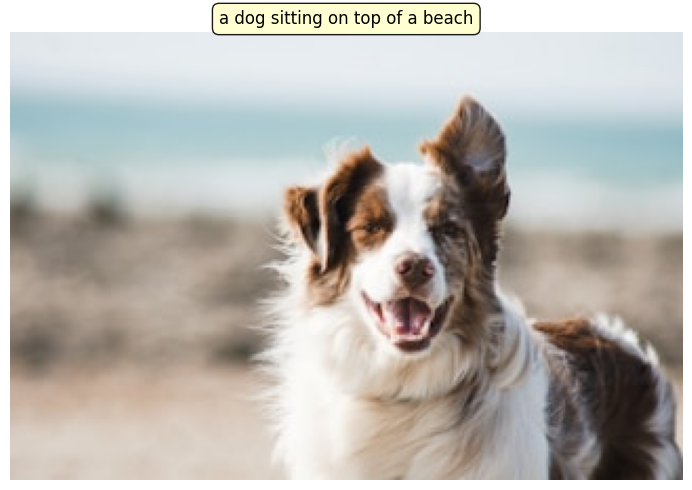

  Saved: runs/captions/url_1.png
  [url_2] -> a black and white cat sitting on top of a chair.


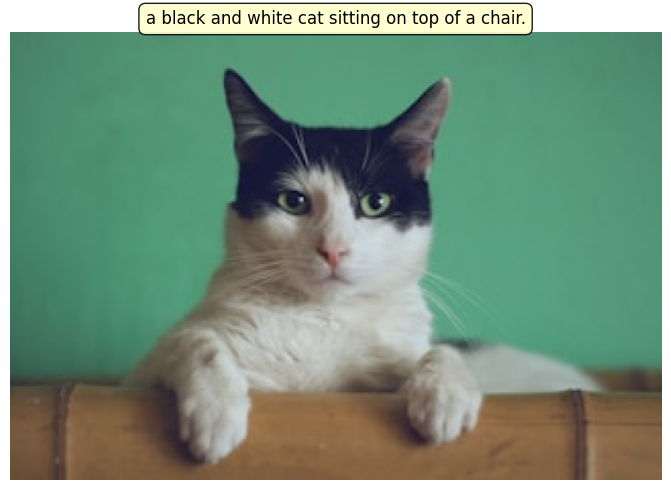

  Saved: runs/captions/url_2.png
  [url_3] -> a small kitten sitting on top of a table.


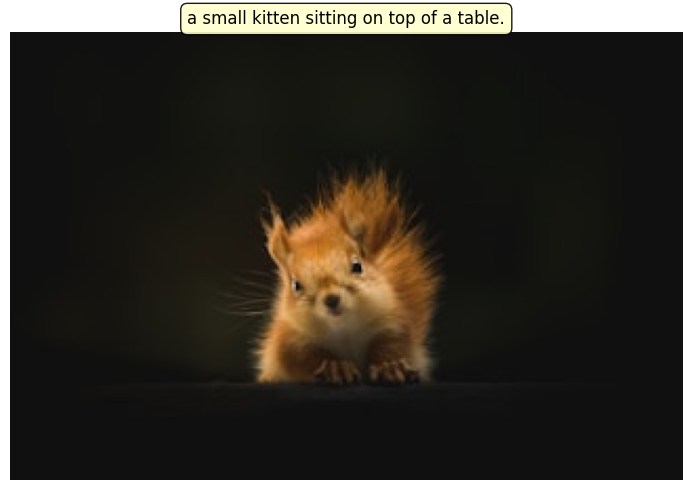

  Saved: runs/captions/url_3.png
  [url_4] -> a group of birds flying over a snow covered mountain.


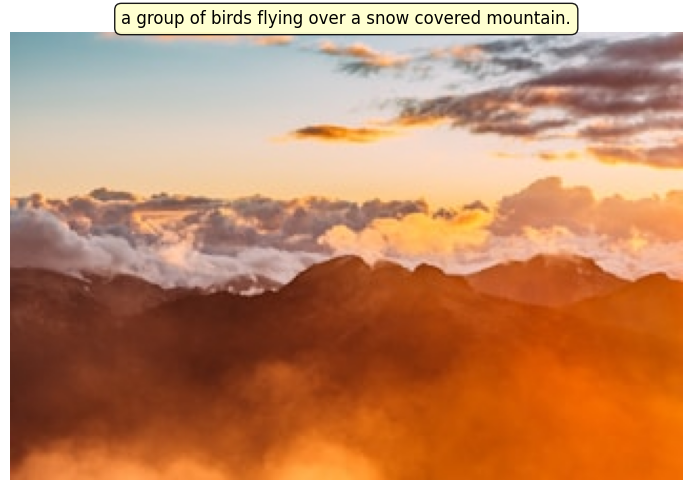

  Saved: runs/captions/url_4.png

Done. Saved to runs/captions/


In [14]:
# Inference: URL / local images
import contextlib, torch, os, sys, io
import urllib.request
from PIL import Image
import torchvision.transforms as T
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display as ipy_display

sys.path.insert(0, "/kaggle/working/project")
for mod in ["model", "beam"]:
    if mod in sys.modules: del sys.modules[mod]

from model import Model
from beam  import beam_search

TEST_URLS = [
    "https://images.unsplash.com/photo-1587300003388-59208cc962cb?w=320",  # dog
    "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=320",  # cat
    "https://images.unsplash.com/photo-1504006833117-8886a355efbf?w=320",  # bear
    "https://images.unsplash.com/photo-1444090542259-0af8fa96557e?w=320",  # street
]
TEST_LOCAL_PATHS = []
BEAM    = 16
CKPT    = "runs/best_rl.pt" if os.path.exists("runs/best_rl.pt") else "runs/best.pt"
OUT_DIR = "runs/captions"
os.makedirs(OUT_DIR, exist_ok=True)

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]
INFER_TF = T.Compose([T.Resize((256, 256)), T.ToTensor(), T.Normalize(MEAN, STD)])

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device} | Checkpoint: {CKPT}")

vocab     = torch.load("vocab.pt", map_location="cpu", weights_only=False)
inv_vocab = {v: k for k, v in vocab.items()}

model = Model(len(vocab)).to(device)
ckpt  = torch.load(CKPT, map_location=device, weights_only=False)
state = ckpt["model"] if "model" in ckpt else ckpt
m     = model.module if hasattr(model, "module") else model
m.load_state_dict(state)
model.eval()
print(f"Model: {sum(p.numel() for p in m.parameters()):,} params")

SKIP = {0, 1, 2, 3}

def load_url(url):
    # Browser UA required — Wikimedia blocks default Python urllib agent
    req = urllib.request.Request(
        url, headers={"User-Agent": "Mozilla/5.0 (compatible; CaptionBot/1.0)"}
    )
    with urllib.request.urlopen(req, timeout=15) as r:
        return Image.open(io.BytesIO(r.read())).convert("RGB")

def caption_pil(pil_img):
    t   = INFER_TF(pil_img).unsqueeze(0).to(device)
    ctx = torch.amp.autocast("cuda") if device == "cuda" else contextlib.nullcontext()
    with torch.no_grad(), ctx:
        enc = m.enc(t)
        ids = beam_search(m, enc, beam=BEAM, max_len=30)
    words = [inv_vocab.get(i, "") for i in ids[1:] if i not in SKIP]
    return " ".join(w for w in words if w)

def show_and_save(pil_img, caption, name):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(pil_img)
    ax.axis("off")
    ax.set_title(caption, fontsize=12, wrap=True,
                 bbox=dict(boxstyle="round,pad=0.4", fc="#ffffcc", alpha=0.9))
    plt.tight_layout()
    out = os.path.join(OUT_DIR, f"{name}.png")
    plt.savefig(out, dpi=120, bbox_inches="tight")
    ipy_display(fig)   # works in Kaggle/Jupyter; plt.show() is silent with Agg
    plt.close()
    print(f"  Saved: {out}")

images = []
for i, url in enumerate(TEST_URLS):
    print(f"Fetching {url[:70]}...")
    try:
        images.append((load_url(url), f"url_{i+1}"))
        print("  OK")
    except Exception as e:
        print(f"  Failed: {e}")

for path in TEST_LOCAL_PATHS:
    images.append((Image.open(path).convert("RGB"),
                   os.path.splitext(os.path.basename(path))[0]))

if not images:
    val_dir = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017"
    print("URL fetch failed — falling back to local val2017 images")
    for fname in sorted(os.listdir(val_dir))[:4]:
        if fname.endswith(".jpg"):
            images.append((Image.open(os.path.join(val_dir, fname)).convert("RGB"),
                           os.path.splitext(fname)[0]))

print(f"\nCaptioning {len(images)} image(s)...\n")
for pil, name in images:
    cap = caption_pil(pil)
    print(f"  [{name}] -> {cap}")
    show_and_save(pil, cap, name)

print(f"\nDone. Saved to {OUT_DIR}/")


## Cell 14 — Reward sanity check (run after Cell 12 evaluate.py)

In [15]:
# Reward sanity check -- run AFTER Cell 12 (evaluate.py)
import json, torch, os
from collections import Counter

vocab     = torch.load("vocab.pt", weights_only=False)
inv_vocab = {v: k for k, v in vocab.items()}
ANN       = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_val2017.json"

if not os.path.exists("results.json"):
    print("Run evaluate.py first (Cell 12)")
else:
    with open("results.json") as f:
        results = json.load(f)

    ann_data = json.load(open(ANN))
    gt_caps  = {}
    for a in ann_data["annotations"]:
        gt_caps.setdefault(a["image_id"], []).append(a["caption"])

    def ngrams(toks, n):
        return Counter(zip(*[toks[i:] for i in range(n)]))

    scores = []
    for r in results[:500]:
        hyp  = r["caption"].lower().split()
        # FIX: default=[] not [[]] -- [[]] inserts a phantom empty reference
        refs = [c.lower().split() for c in gt_caps.get(r["image_id"], [])]
        best = 0.0
        for ref in refs:
            h2, r2 = ngrams(hyp, 2), ngrams(ref, 2)
            th, tr = sum(h2.values()), sum(r2.values())
            if th == 0 or tr == 0: continue
            com = sum((h2 & r2).values())
            p, r_ = com/th, com/tr
            if p+r_ > 0: best = max(best, 2*p*r_/(p+r_))
        scores.append(best)

    # FIX: guard ZeroDivisionError if results[:200] is empty
    if not scores:
        print("No scores computed -- check results.json is non-empty")
    else:
        print(f"Bigram-F1 on {len(scores)} val samples: mean={sum(scores)/len(scores):.4f}")
        print(f"  min={min(scores):.4f}  max={max(scores):.4f}")
        print(f"  % captions with score>0: {100*sum(s>0 for s in scores)/len(scores):.1f}%")

    print("\nSample generated captions:")
    for r in results[:5]:
        refs = gt_caps.get(r["image_id"], ["(no ref)"])
        print(f"  GEN : {r['caption']}")
        print(f"  REF : {refs[0]}")
        print()

Bigram-F1 on 500 val samples: mean=0.3122
  min=0.0000  max=1.0000
  % captions with score>0: 92.8%

Sample generated captions:
  GEN : a black motorcycle parked in front of a building.
  REF : A black Honda motorcycle parked in front of a garage.

  GEN : a computer sitting on top of a desk.
  REF : An office cubicle with four different types of computers.

  GEN : a bathroom with a toilet and a toilet
  REF : A small closed toilet in a cramped space.

  GEN : a man sitting on a chair in front of a building.
  REF : Two women waiting at a bench next to a street.

  GEN : a plate of food on a table
  REF : A beautiful dessert waiting to be shared by two people



## Cell 15 — Per-image caption debug grid

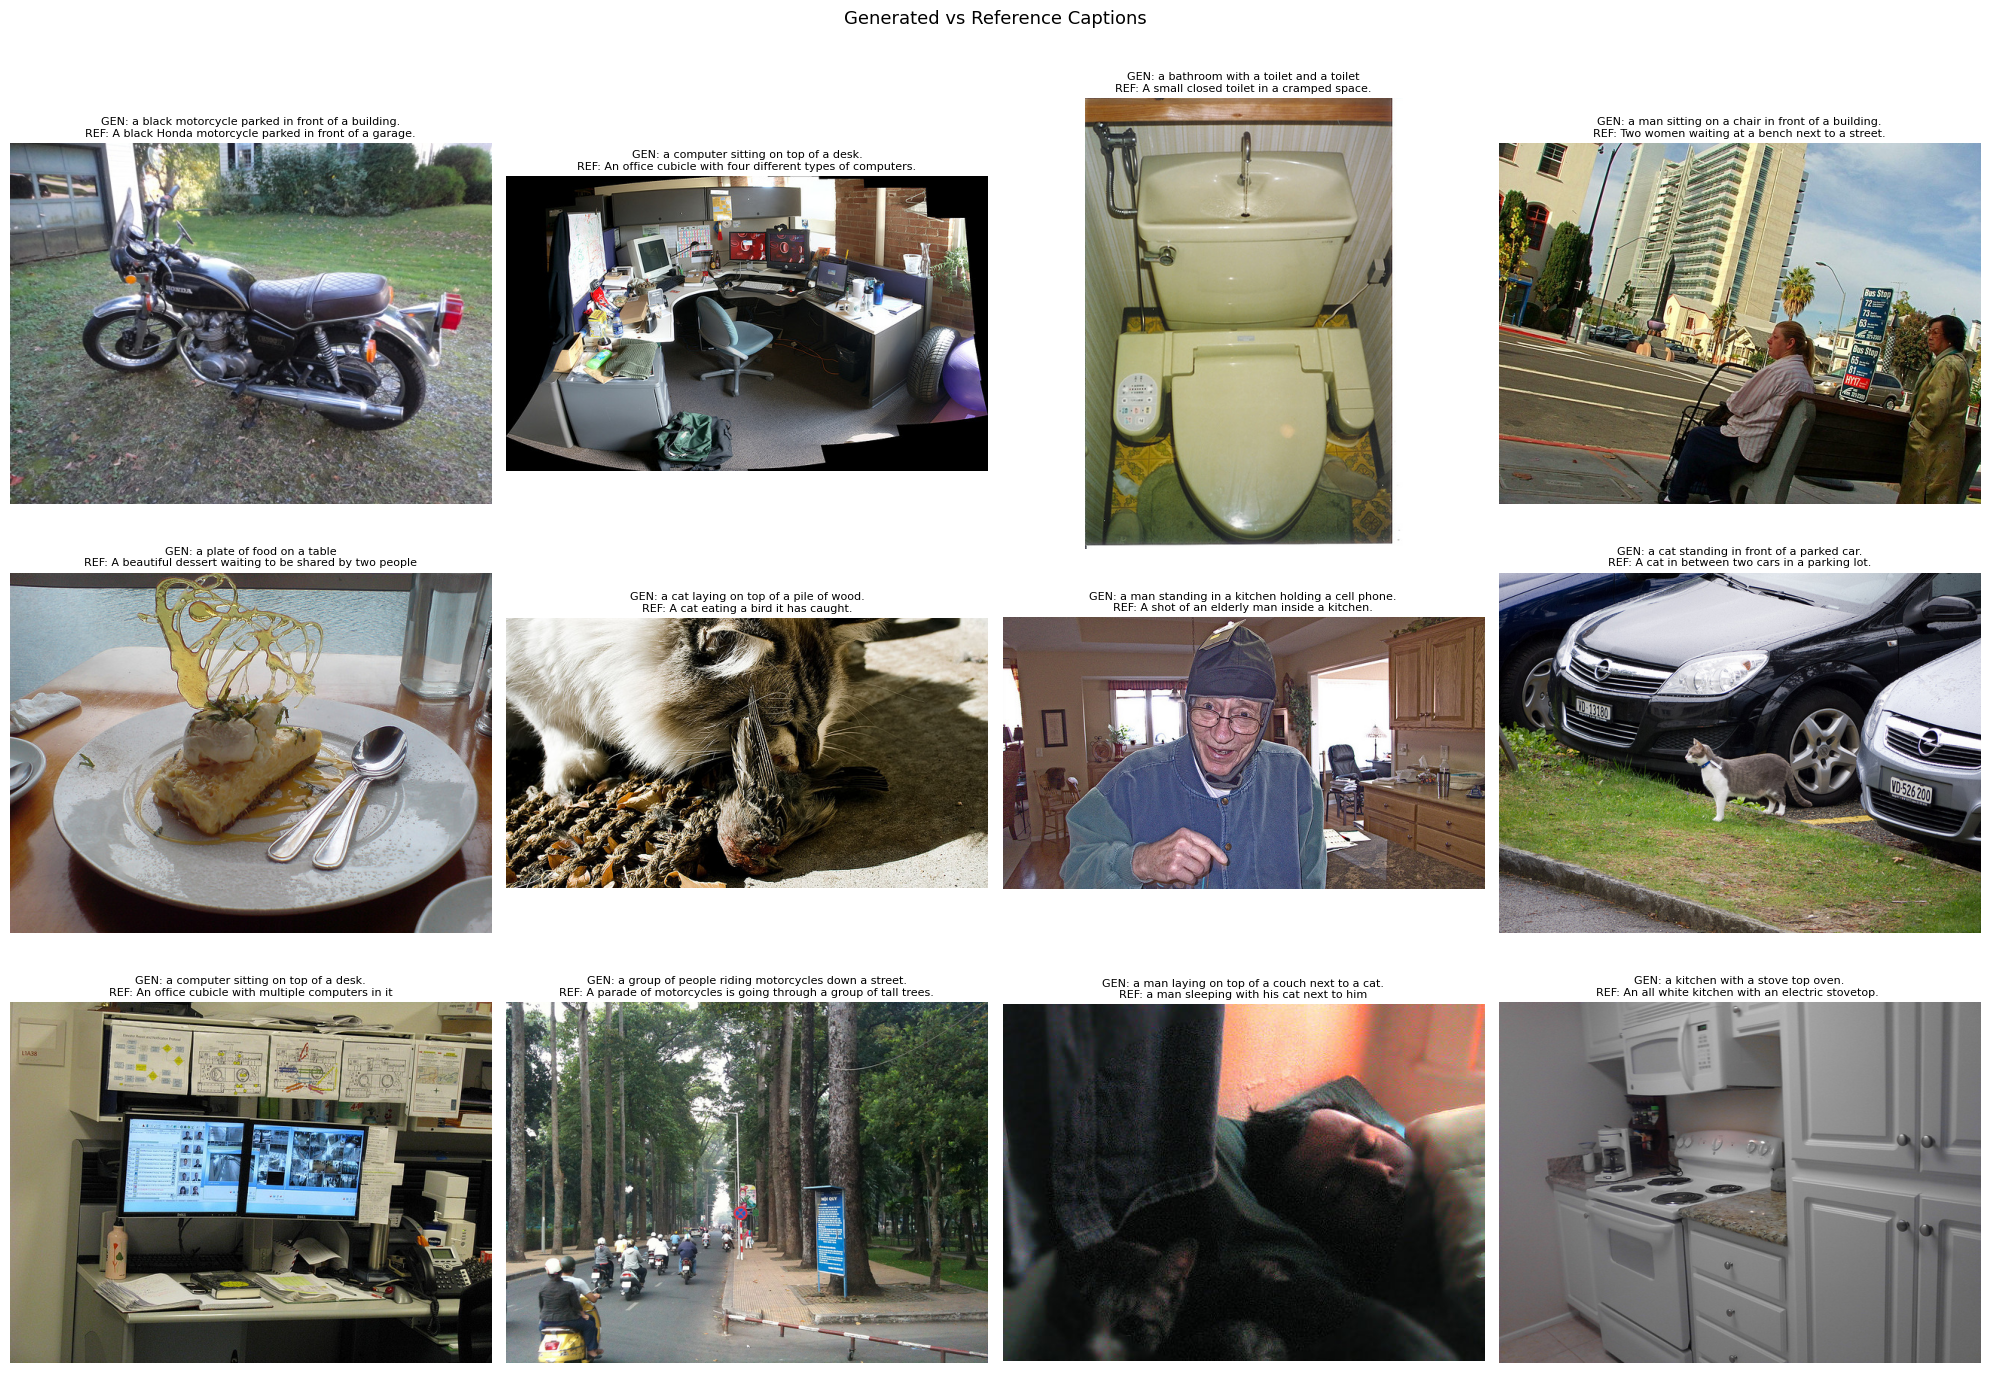

Saved: runs/caption_grid.png


In [16]:
# Per-image caption debug: show image + generated caption + ground truth
import contextlib, sys, torch, json, os
from IPython.display import display as ipy_display
from PIL import Image
import torchvision.transforms as T
import matplotlib
matplotlib.use("Agg")   # FIX: set backend before pyplot import -- works standalone
import matplotlib.pyplot as plt

sys.path.insert(0, "/kaggle/working/project")
for mod in ["model", "beam"]:
    if mod in sys.modules: del sys.modules[mod]
from model import Model
from beam  import beam_search

VAL_DIR = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017"
ANN_VAL = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/annotations/captions_val2017.json"
CKPT    = "runs/best_rl.pt" if os.path.exists("runs/best_rl.pt") else "runs/best.pt"
N_SHOW  = 12

ann_data = json.load(open(ANN_VAL))
gt_caps  = {}
for a in ann_data["annotations"]:
    gt_caps.setdefault(a["image_id"], []).append(a["caption"])
img_ids = list(gt_caps.keys())[:N_SHOW]

MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]
TF   = T.Compose([T.Resize((256, 256)), T.ToTensor(), T.Normalize(MEAN, STD)])
device = "cuda" if torch.cuda.is_available() else "cpu"

vocab     = torch.load("vocab.pt", map_location="cpu", weights_only=False)
inv_vocab = {v: k for k, v in vocab.items()}
model     = Model(len(vocab)).to(device)
ckpt      = torch.load(CKPT, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model"])
model.eval()
m    = model.module if hasattr(model, "module") else model
SKIP = {0, 1, 2, 3}

fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for ax, img_id in zip(axes.flat, img_ids):
    path = os.path.join(VAL_DIR, f"{str(img_id).zfill(12)}.jpg")
    pil  = Image.open(path).convert("RGB")
    t    = TF(pil).unsqueeze(0).to(device)
    # FIX: use contextlib (imported at top) instead of __import__("contextlib")
    ctx  = torch.amp.autocast("cuda") if device == "cuda" else contextlib.nullcontext()
    with torch.no_grad(), ctx:
        enc = m.enc(t)
        ids = beam_search(m, enc, beam=16, max_len=30)
    words = [inv_vocab.get(i, "") for i in ids[1:] if i not in SKIP]
    gen   = " ".join(w for w in words if w)
    ref   = gt_caps[img_id][0]
    ax.imshow(pil)
    ax.axis("off")
    # FIX: truncate ref to 80 chars so long captions don't overflow the title box
    ax.set_title(f"GEN: {gen}\nREF: {ref[:80]}", fontsize=8, wrap=True)

plt.suptitle("Generated vs Reference Captions", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("runs/caption_grid.png", dpi=120, bbox_inches="tight")
ipy_display(fig)
plt.close()
print("Saved: runs/caption_grid.png")